# House Price Prediction with Linear Regression
## Introduction

The goal of this project is to predict house prices using Linear Regression, a supervised machine learning algorithm. The project uses the Ames Housing dataset, which contains information about house characteristics, including living area, overall quality, year built, and garage capacity.

The dataset is explored and preprocessed before training the model. Missing values are handled, categorical variables are encoded, and the data is divided into training and testing sets. The model's performance is evaluated using Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the R² score.

Finally, Linear Regression is compared with Ridge Regression to determine which model performs better on the test dataset.

This project provides practical experience in data analysis, data preprocessing, regression modeling, and model evaluation.

In [ ]:
# 1.Importing Libraries and Loading the Dataset
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge

df=pd.read_csv("AmesHousing.csv")
df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,...,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,...,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,...,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,...,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,...,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,...,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [ ]:
# 2.EDA(Exploratory Data Analysis)
print("1.Number of rows and columns:\n ",df.shape)
print("2.Info:",df.info())
print("3.Describe:\n ",df.describe())
print("4.Number of null values: \n",df.isnull().sum())
print("5.Duplicate rows: \n",df.duplicated().sum())
print("6.Column names: \n",df.columns.tolist())

1.Number of rows and columns:
  (2930, 82)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   object 
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   object 
 7   Alley            198 non-null    object 
 8   Lot Shape        2930 non-null   object 
 9   Land Contour     2930 non-null   object 
 10  Utilities        2930 non-null   object 
 11  Lot Config       2930 non-null   object 
 12  Land Slope       2930 non-null   object 
 13  Neighborhood     2930 non-null   object 
 14  Condition 1      2930 non-null   object 
 15  Condition 2      2930 non-null   object 
 16  Bldg Type        

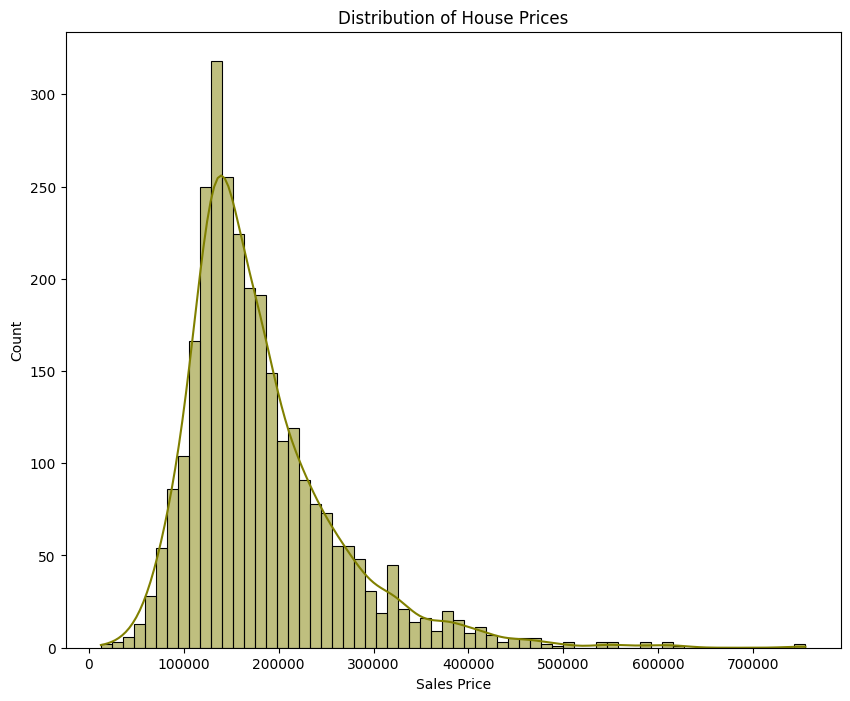

In [ ]:
# Distribution of House Prices
plt.figure(figsize=(10,8))
sns.histplot(df["SalePrice"],kde=True,color="olive")
plt.title("Distribution of House Prices")
plt.xlabel("Sales Price")
plt.show()

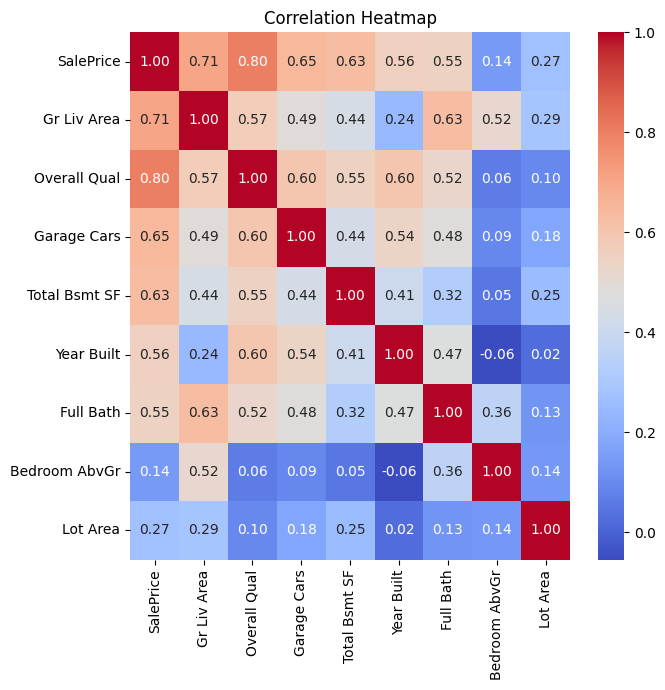

In [ ]:
# 3.Feature Selection and Correlation Analysis
features = [
    "SalePrice",
    "Gr Liv Area",
    "Overall Qual",
    "Garage Cars",
    "Total Bsmt SF",
    "Year Built",
    "Full Bath",
    "Bedroom AbvGr",
    "Lot Area"
]
corr = df[features].corr()
plt.figure(figsize=(7, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
# 4.Data Preprocessing
X = df.drop(
    columns=["SalePrice", "Order", "PID"],
    errors="ignore"
)
Y=df["SalePrice"]
numeric_cols=X.select_dtypes(include=["int64","float64"]).columns.tolist()
categorical_cols=X.select_dtypes(include=["object"]).columns.tolist()

print(f"Numeric columns: {numeric_cols}")
print(f"Categorial columns: {categorical_cols}")


numeric_transformer=Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_transformer=Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

print("Data preprocessing is ready!")

Numeric columns: ['MS SubClass', 'Lot Frontage', 'Lot Area', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces', 'Garage Yr Blt', 'Garage Cars', 'Garage Area', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold']
Categorial columns: ['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC', 'Central Air'

In [ ]:
# 5.Splitting the Dataset into Training and Testing Sets
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)
print("Training Data: ",X_train.shape)
print("Testing Data: ",X_test.shape)

Training Data:  (2344, 79)
Testing Data:  (586, 79)


In [ ]:
# 6.Building and Training the Linear Regression Model
linear_model=Pipeline([
    ("preprocessor",preprocessor),
    ("model",LinearRegression())
])
linear_model.fit(X_train,Y_train)
y_pred=linear_model.predict(X_test)

results=pd.DataFrame({"Actual Price":Y_test.to_numpy(),
                     "Predicted Price":y_pred.round(2)})
results.head(20)

,Actual Price,Predicted Price
0,161000,146044.65
1,116000,109349.49
2,196500,186299.19
3,123600,127674.01
4,126000,140788.45
5,174190,190237.05
6,200000,159915.95
7,148500,142139.26
8,88750,116082.98
9,409900,335593.54


In [ ]:
# 7.Model Evaluation
mse=mean_squared_error(Y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(Y_test,y_pred)
print(f"MSE: {round(mse,2)}")
print(f"RMSE: {round(rmse,2)}")
print(f"R2 score: {round(r2,4)}")

MSE: 913015555.88
RMSE: 30216.15
R2 score: 0.8861


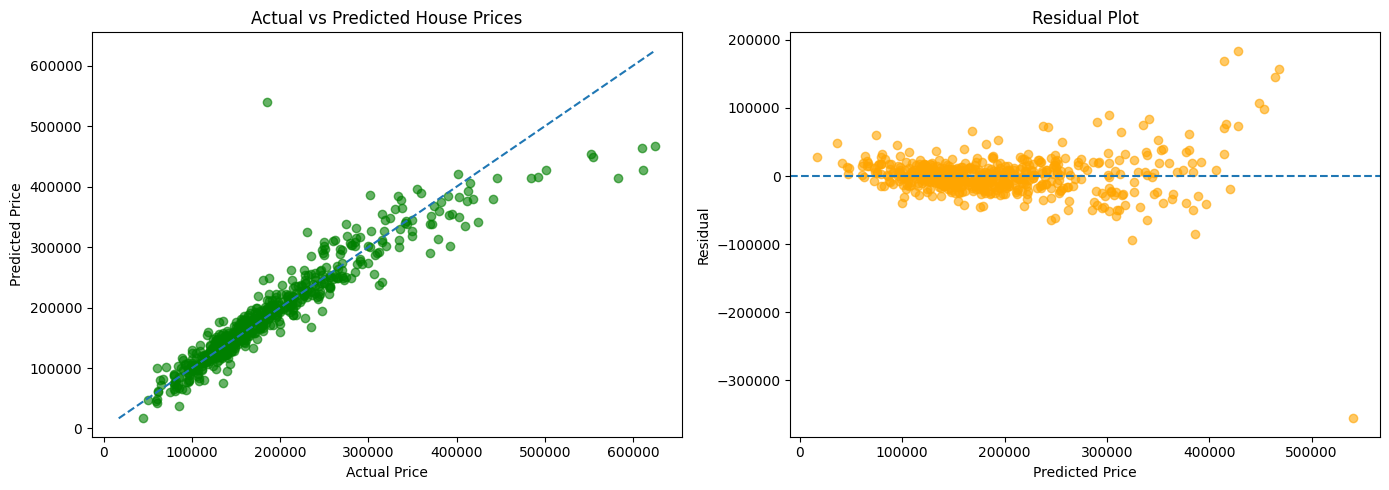

In [ ]:
# 8.Visualizing Predictions and Residuals
residuals = Y_test.to_numpy() - y_pred
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# The first graph
axes[0].scatter(Y_test, y_pred, alpha=0.6,color="green")
low = min(Y_test.min(), y_pred.min())
high = max(Y_test.max(), y_pred.max())
axes[0].plot(
    [low, high],
    [low, high],
    linestyle="--"
)
axes[0].set_title("Actual vs Predicted House Prices")
axes[0].set_xlabel("Actual Price")
axes[0].set_ylabel("Predicted Price")

# The Second graph
axes[1].scatter(y_pred, residuals, alpha=0.6,color="orange")
axes[1].axhline(0, linestyle="--")
axes[1].set_title("Residual Plot")
axes[1].set_xlabel("Predicted Price")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

In [ ]:
# 9.Analyzing Model Coefficients
feature_names = (
    linear_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = (
    linear_model
    .named_steps["model"]
    .coef_
)

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

print("Top 10 positive coefficients:")
display(
    coef_df
    .sort_values("Coefficient", ascending=False)
    .head(10)
)

print("Top 10 negative coefficients: ")
display(
    coef_df
    .sort_values("Coefficient", ascending=True)
    .head(10)
)

Top 10 positive coefficients:


,Feature,Coefficient
91,cat__Neighborhood_StoneBr,53050.131176
137,cat__Roof Matl_WdShngl,43521.206981
84,cat__Neighborhood_NoRidge,40304.740288
272,cat__Pool QC_Ex,37949.794158
281,cat__Misc Feature_Gar2,36917.209478
85,cat__Neighborhood_NridgHt,28195.249991
76,cat__Neighborhood_GrnHill,25826.652699
98,cat__Condition 1_PosN,20454.562824
141,cat__Exterior 1st_BrkFace,19134.743906
261,cat__Garage Qual_Gd,18653.786919


Top 10 negative coefficients: 


,Feature,Coefficient
130,cat__Roof Matl_ClyTile,-49995.395219
274,cat__Pool QC_Gd,-41470.292625
280,cat__Misc Feature_Elev,-32588.313611
49,cat__Lot Shape_IR3,-27060.259307
114,cat__Bldg Type_Twnhs,-20067.845407
283,cat__Misc Feature_Shed,-18906.605383
73,cat__Neighborhood_Edwards,-17304.635089
83,cat__Neighborhood_NWAmes,-16859.939213
80,cat__Neighborhood_Mitchel,-16016.558680
260,cat__Garage Qual_Fa,-15250.509755


In [ ]:
# 10.Comparing Models
ridge_model=Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=10.0))
])

ridge_model.fit(X_train, Y_train)
ridge_pred=ridge_model.predict(X_test)
comparison=pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression"
    ],
    "MSE": [
        mean_squared_error(Y_test, y_pred),
        mean_squared_error(Y_test, ridge_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(Y_test, y_pred)),
        np.sqrt(mean_squared_error(Y_test, ridge_pred))
    ],
    "R2 Score": [
        r2_score(Y_test, y_pred),
        r2_score(Y_test, ridge_pred)
    ]
})

display(comparison.round(4))

,Model,MSE,RMSE,R2 Score
0,Linear Regression,9.130156e+08,30216.1473,0.8861
1,Ridge Regression,1.224742e+09,34996.3160,0.8472


In [ ]:
# Saving Results
results["Ridge Prediction"] = ridge_pred

results.to_csv(
    "house_price_predictions.csv",
    index=False
)

comparison.to_csv(
    "model_comparison.csv",
    index=False
)

print("Files saved successfully!")

Files saved successfully!


# Conclusion

In this project, I developed and evaluated machine learning models to predict house prices using the Ames Housing dataset. I performed exploratory data analysis, analyzed correlations between features, handled missing values, and encoded categorical variables.

The Linear Regression model achieved an **MSE of 913,015,555.88**, an **RMSE of $30,216.15**, and an **R² score of 0.8861**. This indicates that the model explained approximately 88.61% of the variation in house prices in the test dataset.

I also compared Linear Regression with Ridge Regression. The Ridge Regression model achieved an MSE of 1,224,742,000, an RMSE of $34,996.32, and an R² score of 0.8472. Therefore, Linear Regression performed better on the test dataset, producing lower prediction errors and a higher R² score.

Overall, this project demonstrated how regression models can be used for house price prediction and how evaluation metrics help compare model performance. It also improved my understanding of data preprocessing, feature analysis, model evaluation, and machine learning workflows.